# 67 — Zero-shot classification and prompt design

A CLIP-like model can classify an image without a learned classifier head. We encode candidate class descriptions, treat their text embeddings as class prototypes, and select the prototype most similar to the image embedding.

This notebook uses a small synthetic color-and-shape dataset. It is intentionally lightweight: the goal is to see how zero-shot classification, compositional labels, prompt wording, and prompt ensembling fit together.

## Learning goals

By the end, you should be able to:

- convert text embeddings into zero-shot classifier weights;
- explain why the text encoder replaces a fixed learned classification head;
- compare bare class names with descriptive prompt templates;
- ensemble several prompts for the same class;
- evaluate combinations that were held out during contrastive training.

In [1]:
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cs231n_practice.vision_language import clip_contrastive_loss

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# if torch.cuda.is_available():
#     device = torch.device("cuda")
# elif torch.backends.mps.is_available():
#     device = torch.device("mps")
# else:
device = torch.device("cpu")

print("device:", device)

device: cpu


## 1. A compositional image–text dataset

There are three colors and three shapes, giving nine semantic classes. We exclude two color–shape combinations from training. They still use familiar words, so they provide a small test of whether the two encoders learned reusable concepts rather than only memorizing complete labels.

In [2]:
IMAGE_SIZE = 20
COLORS = {
    "red": torch.tensor([0.90, 0.15, 0.12]),
    "green": torch.tensor([0.12, 0.80, 0.22]),
    "blue": torch.tensor([0.12, 0.30, 0.92]),
}
SHAPES = ("circle", "square", "triangle")
CLASS_PAIRS = [(color, shape) for color in COLORS for shape in SHAPES]
HELD_OUT_PAIRS = {("red", "triangle"), ("blue", "square"), ("green", "circle")}
TRAINING_PAIRS = [pair for pair in CLASS_PAIRS if pair not in HELD_OUT_PAIRS]


def render_shape(color_name, shape_name, generator):
    coordinates = torch.arange(IMAGE_SIZE)
    grid_y, grid_x = torch.meshgrid(coordinates, coordinates, indexing="ij")

    center_x = IMAGE_SIZE // 2 + int(torch.randint(-2, 3, (), generator=generator))
    center_y = IMAGE_SIZE // 2 + int(torch.randint(-2, 3, (), generator=generator))
    radius = int(torch.randint(5, 8, (), generator=generator))
    offset_x = grid_x - center_x
    offset_y = grid_y - center_y

    if shape_name == "circle":
        mask = offset_x**2 + offset_y**2 <= radius**2
    elif shape_name == "square":
        mask = (offset_x.abs() <= radius) & (offset_y.abs() <= radius)
    elif shape_name == "triangle":
        vertical_fraction = (offset_y + radius) / (2 * radius)
        mask = (
            (vertical_fraction >= 0)
            & (vertical_fraction <= 1)
            & (offset_x.abs() <= vertical_fraction * radius)
        )
    else:
        raise ValueError(f"Unknown shape: {shape_name}")

    image = 0.04 + 0.04 * torch.rand(3, IMAGE_SIZE, IMAGE_SIZE, generator=generator)
    image[:, mask] = COLORS[color_name][:, None]
    image += 0.025 * torch.randn(image.shape, generator=generator)
    return image.clamp(0, 1)


### Exercise 1 — Inspect every class

Render one example of each class. Put a red title on the combinations held out from training and a black title on the training combinations.

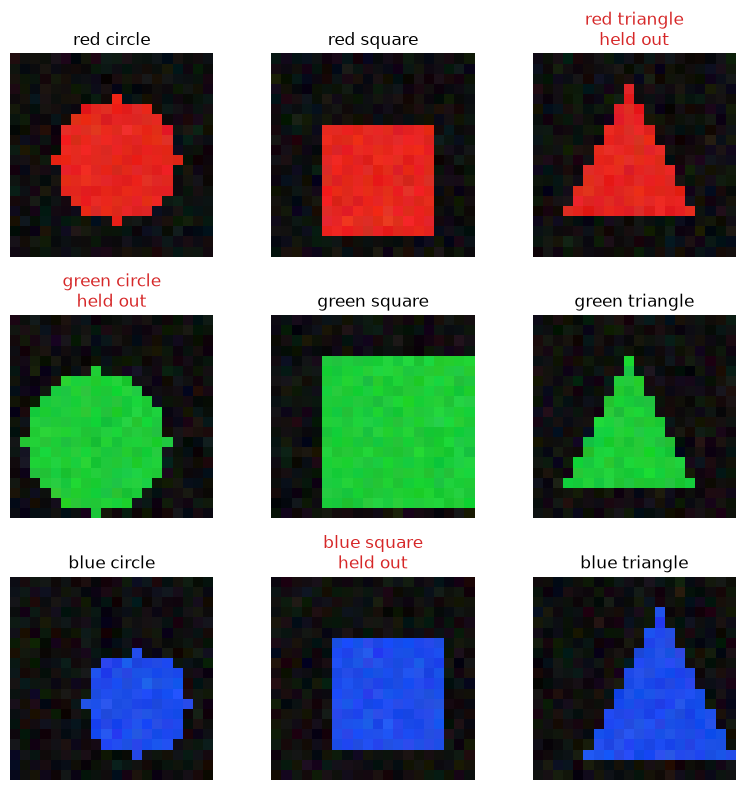

In [3]:
figure, axes = plt.subplots(3, 3, figsize=(8, 8))
generator = torch.Generator().manual_seed(SEED)

for axis, (color_name, shape_name) in zip(axes.ravel(), CLASS_PAIRS):
    # render the requested example and display it as an HWC image.
    image = render_shape(color_name, shape_name, generator)
    axis.imshow(image.permute(1, 2, 0))
    is_held_out = (color_name, shape_name) in HELD_OUT_PAIRS
    axis.set_title(
        f"{color_name} {shape_name}" + ("\nheld out" if is_held_out else ""),
        color="tab:red" if is_held_out else "black",
    )
    axis.axis("off")

plt.tight_layout()

## 2. Minimal text tokenization

A production vision–language model uses a learned subword tokenizer. Here whitespace tokenization is enough: it preserves the important distinction between the reusable color and shape words while keeping all indexing visible.

### Exercise 2 — Build token IDs and a padding mask

For each prompt, place its word IDs into one row and mark only its non-padding positions as valid.

In [4]:
TRAINING_TEMPLATES = (
    "a {color} {shape}",
    "a photo of a {color} {shape}",
    "an image of the {color} {shape}",
)

all_prompt_words = {"<pad>"}
for template in TRAINING_TEMPLATES:
    for color_name, shape_name in CLASS_PAIRS:
        all_prompt_words.update(template.format(color=color_name, shape=shape_name).split())

vocabulary = {word: index for index, word in enumerate(sorted(all_prompt_words))}
PAD_ID = vocabulary["<pad>"]


def tokenize_texts(texts):
    split_texts = [text.lower().split() for text in texts]
    maximum_length = max(len(words) for words in split_texts)
    token_ids = torch.full((len(texts), maximum_length), PAD_ID, dtype=torch.long)
    valid_tokens = torch.zeros((len(texts), maximum_length), dtype=torch.bool)

    for row, words in enumerate(split_texts):
        # convert this row's words to IDs and mark their positions valid.
        for col, word in enumerate(words):
            token_ids[row, col] = vocabulary[word]
            valid_tokens[row, col] = True

    return token_ids, valid_tokens


example_ids, example_mask = tokenize_texts(["red circle", "a photo of a blue triangle"])
print(example_ids)
print(example_mask)

tensor([[ 9,  4,  0,  0,  0,  0],
        [ 1,  8,  7,  1,  3, 12]])
tensor([[ True,  True, False, False, False, False],
        [ True,  True,  True,  True,  True,  True]])


## 3. Tiny image and text encoders

Both encoders must produce vectors with the same width. Contrastive training will arrange those vectors so matching images and descriptions have high cosine similarity.

The text encoder performs masked mean pooling: padding positions must not affect the sentence representation.

### Exercise 3 — Implement both encoder forward passes

Follow the shapes carefully. The image encoder reduces (N, 3, H, W) to (N, D); the text encoder reduces (N, L) token IDs to (N, D).

In [5]:
EMBEDDING_DIMENSION = 24


class TinyImageEncoder(nn.Module):
    def __init__(self, embedding_dimension):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )
        self.projection = nn.Linear(32, embedding_dimension)

    def forward(self, images):
        # extract features, remove the two spatial dimensions, and project.
        features = self.features(images)
        features = features.flatten(1) # Flatten the spatial dimensions (N, 32, 1, 1) -> (N, 32)
        projected_features = self.projection(features)
        return projected_features


class TinyTextEncoder(nn.Module):
    def __init__(self, vocabulary_size, embedding_dimension, padding_id):
        super().__init__()
        self.word_embeddings = nn.Embedding(
            vocabulary_size, embedding_dimension, padding_idx=padding_id
        )
        self.projection = nn.Sequential(
            nn.Linear(embedding_dimension, embedding_dimension),
            nn.ReLU(),
            nn.Linear(embedding_dimension, embedding_dimension),
        )

    def forward(self, token_ids, valid_tokens):
        word_vectors = self.word_embeddings(token_ids)
        # compute a masked mean over the token dimension and project it.
        # Mask the word vectors based on valid_tokens
        masked_word_vectors = word_vectors * valid_tokens.unsqueeze(-1)
        # Compute the sum of valid word vectors
        sum_word_vectors = masked_word_vectors.sum(dim=1)
        # Count the number of valid tokens for each example
        valid_token_counts = valid_tokens.sum(dim=1, keepdim=True)
        # Avoid division by zero by replacing zero counts with one (will result in zero vector)
        valid_token_counts = valid_token_counts.clamp(min=1)
        # Compute the masked mean
        mean_word_vectors = sum_word_vectors / valid_token_counts
        # Project the mean word vectors
        projected_vectors = self.projection(mean_word_vectors)
        return projected_vectors


class TinyDualEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.image_encoder = TinyImageEncoder(EMBEDDING_DIMENSION)
        self.text_encoder = TinyTextEncoder(
            len(vocabulary), EMBEDDING_DIMENSION, PAD_ID
        )

    def forward(self, images, token_ids, valid_tokens):
        return (
            self.image_encoder(images),
            self.text_encoder(token_ids, valid_tokens),
        )

## 4. Contrastive training

Each batch contains one fresh rendering of every training class and a matching description. We vary the prompt template across steps. Unique semantic classes within a batch also avoid treating two examples of the same class as negatives in this simplified one-positive-per-row loss.

### Exercise 4 — Train the dual encoder

Use the symmetric contrastive loss from the preceding notebook, then inspect whether its value decreases.

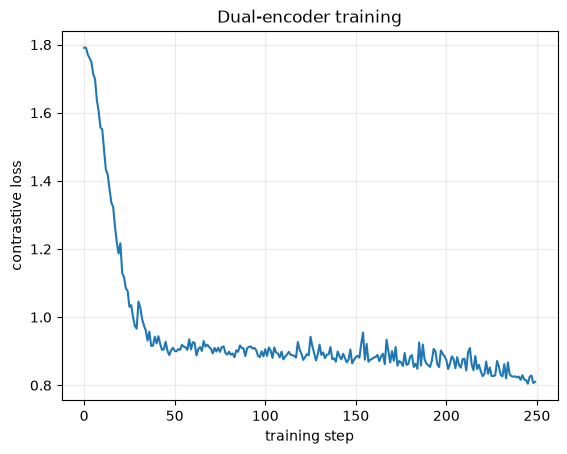

In [6]:
def make_training_batch(step):
    generator = torch.Generator().manual_seed(SEED + step)
    images = []
    texts = []
    for pair_index, (color_name, shape_name) in enumerate(TRAINING_PAIRS):
        images.append(render_shape(color_name, shape_name, generator))
        template = TRAINING_TEMPLATES[(step + pair_index) % len(TRAINING_TEMPLATES)]
        texts.append(template.format(color=color_name, shape=shape_name))
    token_ids, valid_tokens = tokenize_texts(texts)
    return torch.stack(images), token_ids, valid_tokens

torch.manual_seed(SEED)

model = TinyDualEncoder().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
loss_history = []

model.train()
for step in range(250):
    images, token_ids, valid_tokens = make_training_batch(step)
    images = images.to(device)
    token_ids = token_ids.to(device)
    valid_tokens = valid_tokens.to(device)

    # clear gradients, encode the batch, calculate CLIP loss, and update.
    optimizer.zero_grad()
    loss, _ = clip_contrastive_loss(
        *model(images, token_ids, valid_tokens), temperature=0.7
    )
    loss.backward()
    optimizer.step()

    # Record a Python number after implementing the update.
    loss_history.append(loss.item())

plt.plot(loss_history)
plt.xlabel("training step")
plt.ylabel("contrastive loss")
plt.title("Dual-encoder training")
plt.grid(alpha=0.25);

## 5. Text embeddings become classifier weights

For an ordinary linear classifier, each class has a learned weight vector. In zero-shot classification, the text encoder creates that vector from a class prompt.

For prompt ensembling, encode and normalize every prompt separately, average the embeddings belonging to a class, and normalize the average again. The final matrix has shape (number of classes, embedding width).

### Exercise 5 — Build one prototype per class

In [7]:
@torch.no_grad()
def build_text_prototypes(model, class_pairs, templates):
    class_prototypes = []
    for color_name, shape_name in class_pairs:
        prompts = [
            template.format(color=color_name, shape=shape_name)
            for template in templates
        ]
        token_ids, valid_tokens = tokenize_texts(prompts)
        # encode and normalize prompts, average them, then normalize the mean.
        prompt_embeddings = model.text_encoder(token_ids.to(device), valid_tokens.to(device))
        prototype = F.normalize(prompt_embeddings, dim=1).mean(dim=0)
        prototype = F.normalize(prototype, dim=0)  # Normalize the mean vector
        class_prototypes.append(prototype)

    return torch.stack(class_prototypes)


# Expected shape after implementation: (9, 24)
prototypes = build_text_prototypes(model, CLASS_PAIRS, TRAINING_TEMPLATES)
print(prototypes.shape)

torch.Size([9, 24])


## 6. Zero-shot evaluation

We now render all nine classes, including the two unseen combinations. No image classifier is fitted. Classification is simply nearest text prototype under cosine similarity.

### Exercise 6 — Predict and construct a confusion matrix

In [8]:
evaluation_images = []
evaluation_labels = []
generator = torch.Generator().manual_seed(SEED + 10_000)

for class_index, (color_name, shape_name) in enumerate(CLASS_PAIRS):
    for _ in range(30):
        evaluation_images.append(render_shape(color_name, shape_name, generator))
        evaluation_labels.append(class_index)

evaluation_images = torch.stack(evaluation_images)
evaluation_labels = torch.tensor(evaluation_labels)
held_out_class_indices = torch.tensor(
    [index for index, pair in enumerate(CLASS_PAIRS) if pair in HELD_OUT_PAIRS]
)
held_out_examples = torch.isin(evaluation_labels, held_out_class_indices)

print("images:", evaluation_images.shape)
print("labels:", evaluation_labels.shape)
print("held-out examples:", int(held_out_examples.sum()))

images: torch.Size([270, 3, 20, 20])
labels: torch.Size([270])
held-out examples: 90


In [9]:
model.eval()
with torch.no_grad():
    # normalize image embeddings and compare them with text prototypes.
    image_embeddings = F.normalize(model.image_encoder(evaluation_images.to(device)), dim=1)
    prototypes = F.normalize(prototypes.to(device), dim=1)
    similarity_scores = image_embeddings @ prototypes.T
    predictions = similarity_scores.argmax(dim=1)

# calculate overall, seen-combination, and held-out-combination accuracy.
labels_device = evaluation_labels.to(device)
held_out_device = held_out_examples.to(device)

overall_accuracy = (
    (predictions == labels_device).float().mean().item()
)
seen_accuracy = (
    (predictions[~held_out_device] == labels_device[~held_out_device])
    .float()
    .mean()
    .item()
)
held_out_accuracy = (
    (predictions[held_out_device] == labels_device[held_out_device])
    .float()
    .mean()
    .item()
)

print("overall accuracy:", overall_accuracy)
print("seen accuracy:", seen_accuracy)
print("held-out accuracy:", held_out_accuracy)

overall accuracy: 0.6925926208496094
seen accuracy: 0.8722222447395325
held-out accuracy: 0.3333333432674408


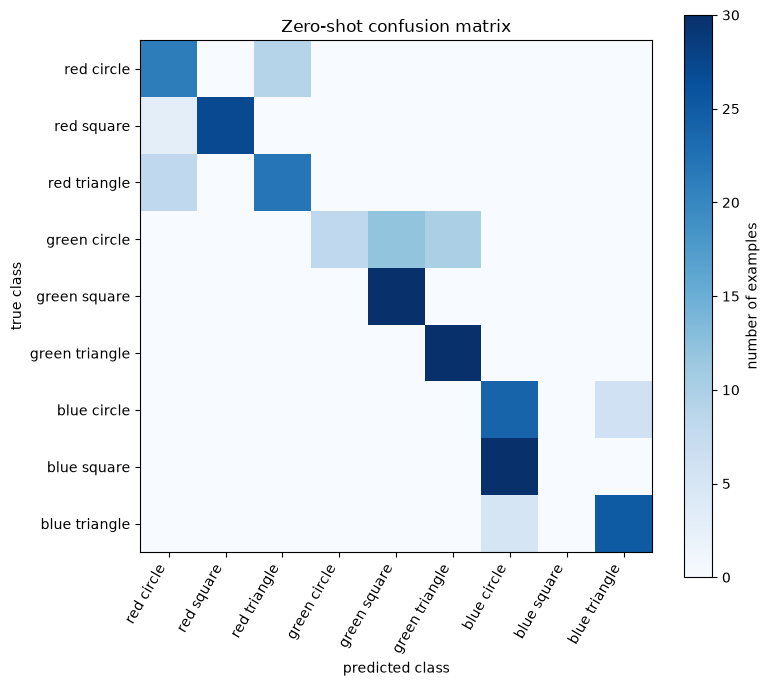

In [10]:
number_classes = len(CLASS_PAIRS)
confusion = torch.zeros(number_classes, number_classes, dtype=torch.long)

# count every (target, prediction) pair in the confusion matrix.
predictions_cpu = predictions.cpu()

for target, prediction in zip(evaluation_labels, predictions_cpu):
    confusion[target, prediction] += 1

figure, axis = plt.subplots(figsize=(8, 7))
image_artist = axis.imshow(confusion.numpy(), cmap="Blues")
class_names = [f"{color} {shape}" for color, shape in CLASS_PAIRS]
axis.set_xticks(range(number_classes), class_names, rotation=60, ha="right")
axis.set_yticks(range(number_classes), class_names)
axis.set_xlabel("predicted class")
axis.set_ylabel("true class")
axis.set_title("Zero-shot confusion matrix")
figure.colorbar(image_artist, ax=axis, label="number of examples")
plt.tight_layout()

## 7. Prompt choice is part of the classifier

The text encoder was trained on natural-looking phrases, so a bare label and a descriptive sentence need not occupy the same location in embedding space. Prompt ensembling reduces dependence on one particular wording, but it cannot guarantee an improvement—especially for a tiny model and dataset.

### Exercise 7 — Compare three prompting strategies

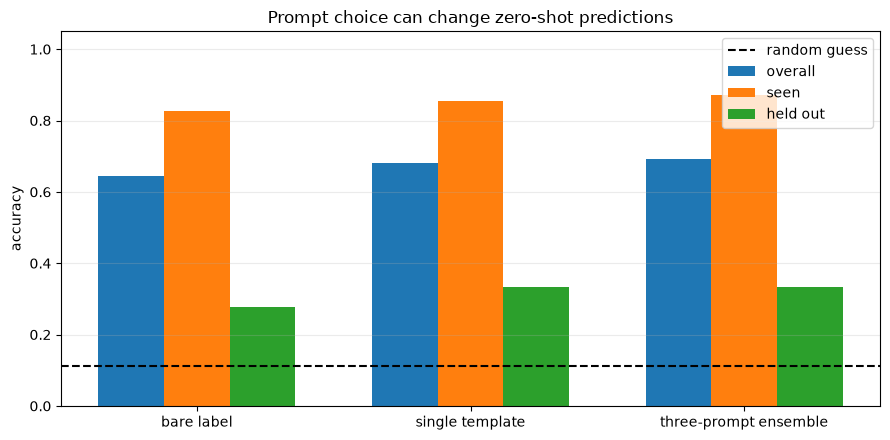

In [13]:
PROMPT_SETS = {
    "bare label": ("{color} {shape}",),
    "single template": ("a photo of a {color} {shape}",),
    "three-prompt ensemble": TRAINING_TEMPLATES,
}

prompt_results = {}
for prompt_name, templates in PROMPT_SETS.items():
    # Each prompt set creates a different zero-shot classifier. Its rows are
    # text-derived class weights rather than parameters fitted to image labels.
    prompt_prototypes = build_text_prototypes(model, CLASS_PAIRS, templates)
    prompt_scores = image_embeddings @ prompt_prototypes.T
    prompt_predictions = prompt_scores.argmax(dim=1)
    correct = prompt_predictions == labels_device

    prompt_results[prompt_name] = {
        "overall": correct.float().mean().item(),
        "seen": correct[~held_out_device].float().mean().item(),
        "held out": correct[held_out_device].float().mean().item(),
    }

metric_names = ("overall", "seen", "held out")
x_positions = np.arange(len(PROMPT_SETS))
bar_width = 0.24

figure, axis = plt.subplots(figsize=(9, 4.5))
for metric_index, metric_name in enumerate(metric_names):
    values = [result[metric_name] for result in prompt_results.values()]
    axis.bar(
        x_positions + (metric_index - 1) * bar_width,
        values,
        width=bar_width,
        label=metric_name,
    )

axis.axhline(1 / len(CLASS_PAIRS), color="black", linestyle="--", label="random guess")
axis.set_xticks(x_positions, PROMPT_SETS.keys())
axis.set_ylim(0, 1.05)
axis.set_ylabel("accuracy")
axis.set_title("Prompt choice can change zero-shot predictions")
axis.legend()
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()

## 8. Inspect confident mistakes

A single accuracy hides which concept failed. A wrong color with the right shape suggests a different failure from a right color with the wrong shape. Inspect several high-confidence errors from the prompt ensemble.

### Exercise 8 — Interpret the model's mistakes

Run the visualization, identify whether each error changes color or shape, and use those observations in the final reflection.

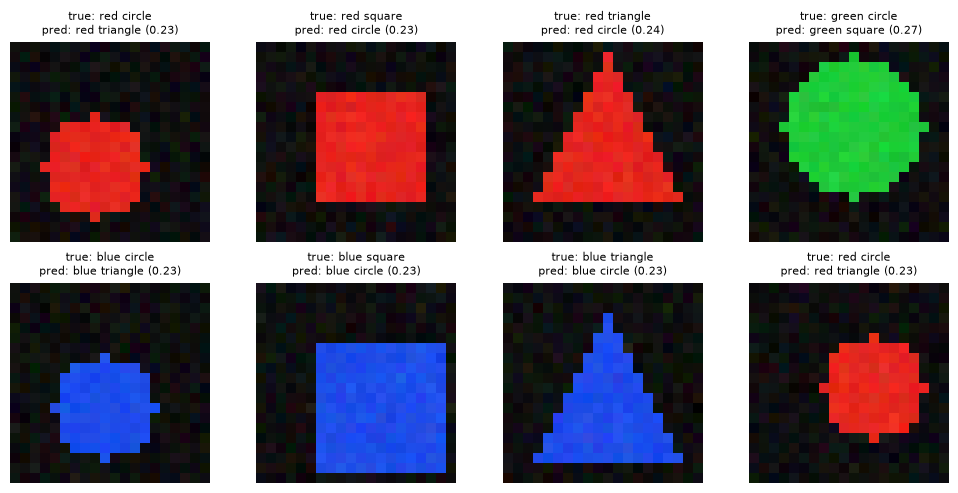

In [14]:
# Recompute predictions from the prompt ensemble so this cell is self-contained.
ensemble_prototypes = build_text_prototypes(model, CLASS_PAIRS, TRAINING_TEMPLATES)
ensemble_scores = image_embeddings @ ensemble_prototypes.T
ensemble_probabilities = F.softmax(ensemble_scores, dim=1)
ensemble_confidences, ensemble_predictions = ensemble_probabilities.max(dim=1)

# Move the evaluation results to the CPU for selection and plotting.
ensemble_predictions_cpu = ensemble_predictions.cpu()
ensemble_confidences_cpu = ensemble_confidences.cpu()
mistake_indices = torch.where(ensemble_predictions_cpu != evaluation_labels)[0]

# Taking the eight most confident mistakes globally can let one problematic
# class occupy every panel. Instead, sort mistakes within each true class and
# select them round by round: first one per class, then a second per class, etc.
mistakes_by_class = []
for class_index in range(number_classes):
    class_mistakes = mistake_indices[
        evaluation_labels[mistake_indices] == class_index
    ]
    confidence_order = torch.argsort(
        ensemble_confidences_cpu[class_mistakes], descending=True
    )
    mistakes_by_class.append(class_mistakes[confidence_order].tolist())

selected_mistakes = []
round_index = 0
while len(selected_mistakes) < 8:
    added_example = False
    for class_mistakes in mistakes_by_class:
        if round_index < len(class_mistakes):
            selected_mistakes.append(class_mistakes[round_index])
            added_example = True
            if len(selected_mistakes) == 8:
                break
    if not added_example:
        break
    round_index += 1

figure, axes = plt.subplots(2, 4, figsize=(10, 5))
for axis, example_index in zip(axes.ravel(), selected_mistakes):
    target_index = int(evaluation_labels[example_index])
    predicted_index = int(ensemble_predictions_cpu[example_index])
    axis.imshow(evaluation_images[example_index].permute(1, 2, 0))
    axis.set_title(
        f"true: {class_names[target_index]}\n"
        f"pred: {class_names[predicted_index]} "
        f"({ensemble_confidences_cpu[example_index]:.2f})",
        fontsize=8,
    )
    axis.axis("off")

for axis in axes.ravel()[len(selected_mistakes):]:
    axis.axis("off")

plt.tight_layout()

## 9. What this toy experiment does—and does not—show

The held-out combinations are useful for testing simple compositional reuse: both constituent words appeared during training, but not together. This is much narrower than real CLIP zero-shot transfer, where a large pretrained model is evaluated on new datasets and potentially new visual concepts.

A poor held-out result does not prove that contrastive learning cannot compose concepts. Here the encoders, data variety, vocabulary, and training budget are all tiny. Conversely, a good result on a few synthetic combinations is not evidence of broad visual-language understanding.

**Stability note.** Held-out accuracy in this small experiment can vary considerably with the random initialization, selected held-out combinations, temperature, learning rate, number of training steps, and compute device. The model has little data and several equally plausible solutions, so small optimization changes can lead to different unseen-combination predictions. Treat one run as an observation rather than a stable benchmark; a stronger comparison would repeat each configuration with several seeds and report the mean and variation.

## Reflection

1. In what sense do text prototypes replace the weight matrix of a conventional classifier?

   Each normalized text prototype acts like one row of a classifier's weight matrix. An image is classified by taking dot products with these text-derived weights instead of weights learned from labeled images.

2. Why can zero-shot classification recognize a class for which no classifier-specific training examples were supplied?

   Contrastive training places visual and textual concepts in a shared embedding space. We can therefore describe a new class with text and compare its embedding directly with an image embedding.

3. Why might a descriptive prompt outperform a bare class name?

   A descriptive prompt resembles the sentences used during training and supplies useful context, whereas an isolated label may have a less suitable embedding.

4. What does averaging several prompt embeddings try to make the classifier less sensitive to?

   It reduces sensitivity to the wording of any single template by combining several descriptions of the same class.

5. Compare seen and held-out accuracy. What does the gap suggest about compositional generalization in this experiment?

   Seen accuracy is substantially higher than held-out accuracy. The model learns observed pairs reliably but only partly recombines familiar colors and shapes; the exact gap is unstable across runs.

6. From the confusion matrix and confident mistakes, did the model confuse color, shape, or both most often?

   Shape was confused more often than color in this run. Color is a strong global visual cue, while distinguishing the simple shape boundaries is harder for this tiny encoder.